# ASCENT 4-130, Module 5 : Autonomie des systèmes robotisés

**Jour 2, deuxième séquence (2 heures).** Boucle perception, décision, action ; gestion des incertitudes dans un environnement dynamique ; intégration d'algorithmes d'apprentissage.

**Le fil rouge.** Le robot de l'entrepôt doit rejoindre son objectif alors que ses capteurs sont bruités, que ses roues glissent, que des chariots circulent et qu'une palette peut être déposée sur son chemin. Un robot autonome est un robot qui continue à bien se comporter quand le monde ne correspond plus exactement à son modèle.

**Objectifs.**
- Écrire explicitement la boucle perception, décision, action.
- Modéliser les incertitudes de perception et d'action, et mesurer leurs effets.
- Implémenter un filtre bayésien discret pour estimer la position du robot.
- Comparer une politique simple à une politique améliorée.
- Apprendre une politique de navigation par renforcement (Q-learning).

**Durée indicative du TP (75 minutes).**

| Partie | Contenu | Durée |
|---|---|---|
| 1 | La boucle perception, décision, action | 10 min |
| 2 | Les incertitudes | 10 min |
| 3 | Filtre bayésien discret | 20 min |
| 4 | Politique simple contre politique améliorée | 15 min |
| 5 | Apprentissage par renforcement | 15 min |
| 6 | Export des traces | 5 min |

Le notebook est livré exécuté : les sorties visibles servent de résultats de repli.

## Avant de commencer

**Ce qu'il faut connaître.** Chaque notion utilisée ici a sa leçon guidée dans le module 0 du site. Si l'une d'elles vous est nouvelle, commencez par là (15 à 20 minutes par leçon, théorie et atelier de construction compris) :

- [État réel et observation](https://martinobettucci.github.io/4-120/#/module/0/etat)
- [Croyance et filtre bayésien](https://martinobettucci.github.io/4-120/#/module/0/croyance)
- [Processus de décision markovien et politique](https://martinobettucci.github.io/4-120/#/module/0/mdp)
- [Apprentissage par renforcement](https://martinobettucci.github.io/4-120/#/module/0/qlearning)
- [Exploration et exploitation](https://martinobettucci.github.io/4-120/#/module/0/exploration)

**Comment travailler dans ce notebook.** Pour chaque partie, suivez quatre temps :

1. **Lire** l'explication qui précède le code.
2. **Prédire** ce que la cellule va afficher, avant de l'exécuter. Notez votre prédiction, même approximative.
3. **Exécuter**, puis comparer le résultat à votre prédiction. Un écart est une information : cherchez d'où il vient.
4. **Modifier** une valeur de la cellule `PARAMETRES`, relancer, et expliquer en une phrase ce qui a changé.

**Dans les exercices**, l'aide est graduée : essayez d'abord seul, relisez ensuite l'exemple qui précède, et n'ouvrez la « Solution possible » qu'après un essai. Comparer sa propre tentative à la solution apprend davantage que la lire directement.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ascent_agents import ACTIONS, Entrepot, creer_scenario, detecter_appareil, fixer_graines, simuler
from ascent_agents.agents import AgentHybride, a_etoile, action_vers
from ascent_agents.incertitude import AgentNaif, AgentRobuste, FiltreHistogramme
from ascent_agents.lot import NOMS_ACTIONS, AgentAppris, q_learning_lot
from ascent_agents.monde import RAYONS, Evenement
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, ROUGE, VERT, dessiner_monde, dessiner_trace, style

APPAREIL = detecter_appareil()
fixer_graines(4130)
style()
RESULTATS = Path("resultats")
RESULTATS.mkdir(exist_ok=True)

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## Partie 1. La boucle perception, décision, action

Un système autonome répète sans fin trois opérations :

1. **Percevoir** : lire les capteurs. Le robot n'accède jamais à l'état réel du monde, seulement à une observation.
2. **Décider** : choisir une action à partir de l'observation et de sa mémoire (carte, plan, croyance).
3. **Agir** : envoyer la commande aux effecteurs. Le monde évolue, y compris sans le robot.

La fonction `simuler` du paquet fait ce travail et produit une trace. Écrivons ici la boucle en entier, avec une politique volontairement simple : suivre le plus court chemin calculé sur la carte, et attendre si le lidar voit un obstacle sur la prochaine cellule.

Entrepôt vide
  objectif atteint : True, 26 étapes, dont 0 en attente, 0 collision(s)
Palette imprévue
  étape  2 : événement imprévu [{'type': 'palette', 'cellule': [4, 7]}]
  étape  8 : obstacle devant, attente
  étape  9 : obstacle devant, attente
  étape 10 : obstacle devant, attente
  objectif atteint : False, 80 étapes, dont 72 en attente, 0 collision(s)
Chariots en circulation
  étape 20 : obstacle devant, attente
  étape 21 : obstacle devant, attente
  étape 22 : obstacle devant, attente
  objectif atteint : False, 80 étapes, dont 60 en attente, 0 collision(s)


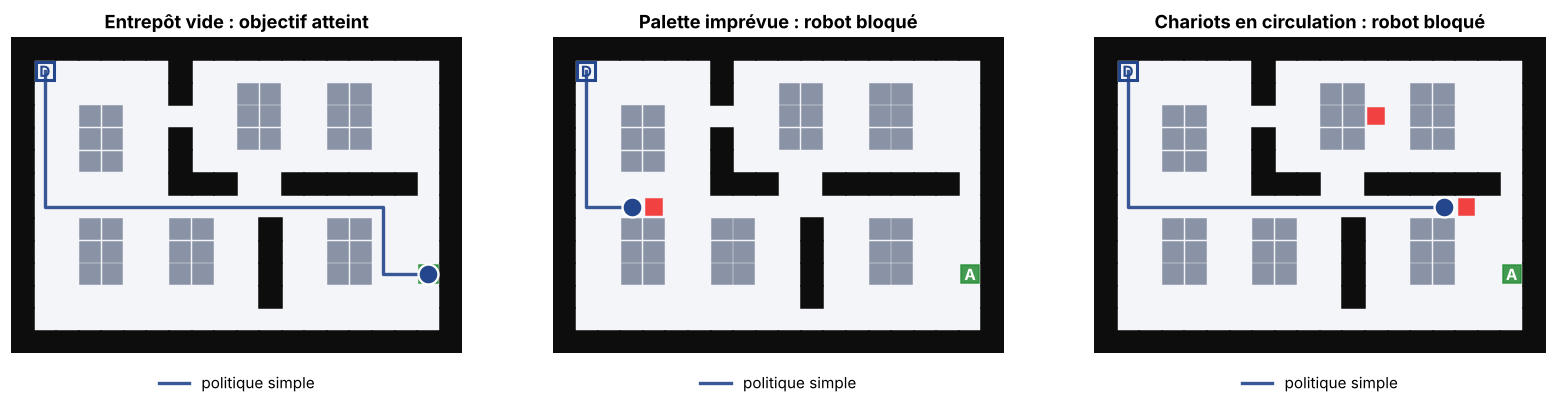

In [3]:
def boucle_autonomie(monde, max_etapes=80, verbeux=True):
    """Boucle perception, décision, action écrite explicitement. Retourne la liste des positions réelles."""
    observation = monde.reinitialiser()                       # première perception
    positions = [monde.robot]
    attentes = 0
    for _ in range(max_etapes):
        # DÉCIDER : planifier depuis la position perçue, puis vérifier le lidar.
        position = tuple(observation["position"])
        plan, _ = a_etoile(monde, position, monde.objectif)
        if plan is None or len(plan) < 2:
            action = "ATTENDRE"
        else:
            action = action_vers(plan[0], plan[1])
            if observation["lidar"][action] <= 1:             # obstacle juste devant
                action = "ATTENDRE"
        # AGIR : le monde avance d'une étape.
        resultat = monde.avancer(action)
        positions.append(monde.robot)
        if verbeux and resultat["evenements"]:
            print(f"  étape {observation['etape']:2d} : événement imprévu {resultat['evenements']}")
        if verbeux and action == "ATTENDRE" and attentes < 3:
            print(f"  étape {observation['etape']:2d} : obstacle devant, attente")
        attentes += action == "ATTENDRE"
        if resultat["arrive"]:
            break
        # PERCEVOIR : nouvelle observation.
        observation = monde.observer()
    if verbeux:
        print(f"  objectif atteint : {resultat['arrive']}, {len(positions) - 1} étapes, dont {attentes} en attente, {monde.collisions} collision(s)")
    return positions, resultat["arrive"]


# Événement imprévu utilisé dans tout le notebook : une palette déposée à l'étape 3 sur le chemin du robot.
PALETTE = Evenement(3, (4, 7))

scenarios = {
    "Entrepôt vide": creer_scenario("entrepot", chariots=False),
    "Palette imprévue": creer_scenario("entrepot", chariots=False, evenements=[PALETTE]),
    "Chariots en circulation": creer_scenario("entrepot"),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (nom, monde) in zip(axes, scenarios.items()):
    print(nom)
    positions, arrive = boucle_autonomie(monde)
    dessiner_monde(monde, ax, trajectoires={"politique simple": positions}, obstacles=monde.obstacles_dynamiques(), robot=monde.robot,
                   titre=f"{nom} : {'objectif atteint' if arrive else 'robot bloqué'}")
plt.show()

La politique « attendre » suffit dans un entrepôt vide. Face à une palette immobile, le robot reste bloqué indéfiniment. Face à un chariot qui arrive en sens inverse, c'est un **interblocage** : le chariot cède le passage au robot, le robot attend le chariot, et plus rien ne bouge. L'agent hybride du module 3 mémorise l'obstacle et replanifie : il passe dans les deux cas.

{'succes': True, 'etapes': 34, 'collisions': 0}
étape  8 : Obstacle imprévu : replanification, détour par N
étape 22 : Obstacle imprévu : replanification, détour par O


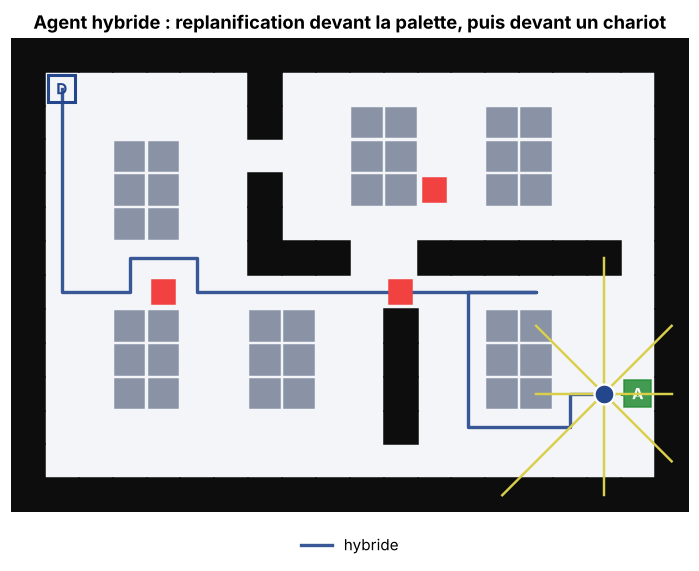

In [4]:
trace = simuler(creer_scenario("entrepot", evenements=[PALETTE]), AgentHybride(), module=5)
print({k: trace.bilan[k] for k in ("succes", "etapes", "collisions")})
for e in trace.etapes:
    if e["decision"].get("couche") == "reactive":
        print(f"étape {e['t']:2d} : {e['decision']['raison']}")
dessiner_trace(trace, titre="Agent hybride : replanification devant la palette, puis devant un chariot")
plt.show()

## Partie 2. Les incertitudes

Jusqu'ici, le robot connaissait sa position exacte et ses actions réussissaient toujours. Le simulateur propose quatre sources d'incertitude :

| Paramètre | Signification |
|---|---|
| `bruit_lidar` | écart type du bruit sur chaque distance mesurée, en cellules |
| `perte_lidar` | probabilité qu'un rayon ne retourne rien (portée maximale lue) |
| `bruit_position` | écart type du bruit sur la position mesurée, en cellules |
| `glissement` | probabilité qu'un déplacement ne s'exécute pas (le robot reste sur place) |

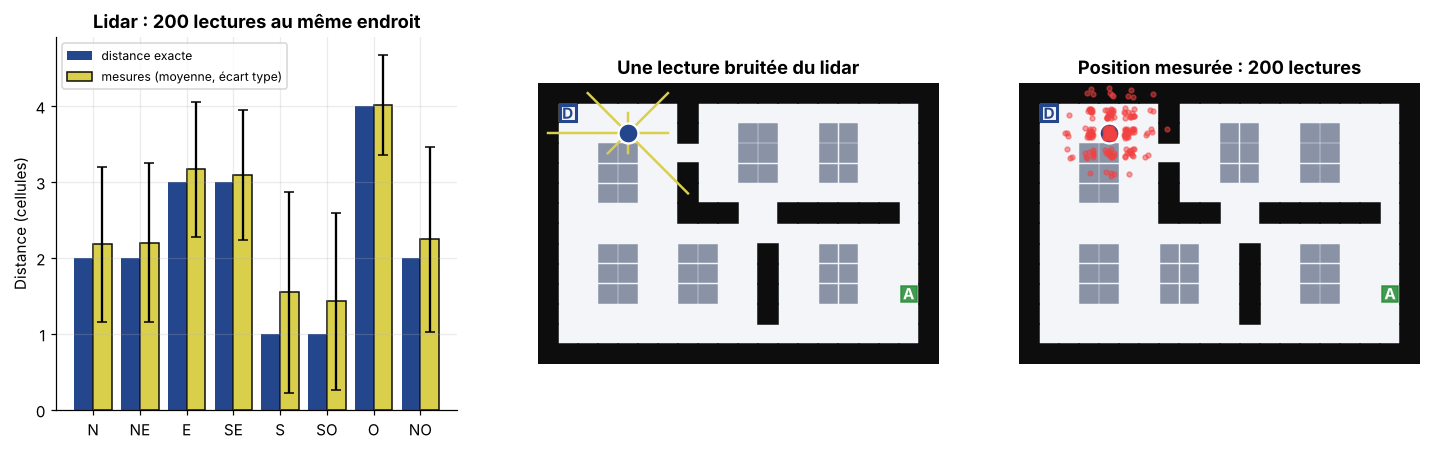

Part des positions mesurées qui tombent dans un mur ou un rayonnage : 20 %


In [5]:
# PARAMÈTRES MODIFIABLES : niveau d'incertitude.
PARAMETRES_BRUIT = {
    "bruit_lidar": 0.5,
    "perte_lidar": 0.05,
    "bruit_position": 0.8,
    "glissement": 0.15,
}
monde = creer_scenario("entrepot", chariots=False, graine=4130, **PARAMETRES_BRUIT)
monde.reinitialiser()
for action in ["E", "E", "S", "S", "S", "E"]:
    monde.avancer(action)

exact = monde.lidar_exact(monde.robot)
mesures = [monde.observer() for _ in range(200)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
noms = list(RAYONS)
moyenne = [np.mean([m["lidar"][r] for m in mesures]) for r in noms]
ecart = [np.std([m["lidar"][r] for m in mesures]) for r in noms]
axes[0].bar(np.arange(8) - 0.2, [exact[r] for r in noms], 0.4, color=BLEU, label="distance exacte")
axes[0].bar(np.arange(8) + 0.2, moyenne, 0.4, yerr=ecart, color=JAUNE, edgecolor=NOIR, capsize=3, label="mesures (moyenne, écart type)")
axes[0].set_xticks(range(8), noms)
axes[0].set_ylabel("Distance (cellules)")
axes[0].set_title("Lidar : 200 lectures au même endroit")
axes[0].legend(fontsize=8)
dessiner_monde(monde, axes[1], robot=monde.robot, lidar=mesures[0]["lidar"], titre="Une lecture bruitée du lidar")
xs = [m["position"][0] + 0.5 + np.random.uniform(-0.25, 0.25) for m in mesures]
ys = [m["position"][1] + 0.5 + np.random.uniform(-0.25, 0.25) for m in mesures]
dessiner_monde(monde, axes[2], robot=monde.robot, titre="Position mesurée : 200 lectures")
axes[2].scatter(xs, ys, s=10, color=ROUGE, alpha=0.5, zorder=8)
plt.show()
dans_obstacle = np.mean([not monde.est_libre_statique(tuple(m["position"])) for m in mesures])
print(f"Part des positions mesurées qui tombent dans un mur ou un rayonnage : {100 * dans_obstacle:.0f} %")

Une partie des positions mesurées tombe dans un rayonnage : la mesure brute est parfois physiquement impossible. Un agent qui lui fait confiance replanifie depuis des positions fausses, hésite et perd du temps.

### Effet du glissement sur une exécution en boucle ouverte

L'agent délibératif du module 3 déroule son plan sans regarder ses capteurs. Avec du glissement, chaque action manquée le décale par rapport à son plan.

In [6]:
from ascent_agents.agents import AgentDeliberatif

lignes = []
for glissement in [0.0, 0.05, 0.15, 0.3]:
    bilans = [simuler(creer_scenario("entrepot", chariots=False, glissement=glissement, graine=g), AgentDeliberatif(), max_etapes=80).bilan for g in range(20)]
    lignes.append({"glissement": glissement, "taux de succès (%)": 100 * np.mean([b["succes"] for b in bilans]),
                   "collisions moyennes": np.mean([b["collisions"] for b in bilans])})
pd.DataFrame(lignes)

,glissement,taux de succès (%),collisions moyennes
0,0.00,100.0,0.00
1,0.05,15.0,3.85
2,0.15,0.0,8.10
3,0.30,0.0,8.30


## Partie 3. Filtre bayésien discret

Plutôt que de croire une mesure, le robot entretient une **croyance** : une probabilité pour chaque cellule libre d'être sa position. La croyance est mise à jour en deux temps à chaque étape.

**Prédiction** (après une action). La probabilité se déplace dans le sens de l'action. Avec un glissement g, une part (1 - g) avance et une part g reste sur place. La croyance s'étale : agir fait perdre de l'information.

**Correction** (après une mesure). Chaque cellule est pondérée par la vraisemblance de la mesure : « si j'étais dans cette cellule, quelle serait la probabilité de lire ce lidar ? ». On multiplie puis on normalise (règle de Bayes) :

croyance(cellule) ∝ vraisemblance(mesure | cellule) × croyance prédite(cellule)

La croyance se concentre : mesurer fait gagner de l'information.

### 3.1 Un exemple à une dimension

Un couloir de 10 cases, avec des portes aux cases 1, 4 et 8. Le capteur indique « porte » ou « mur » et se trompe une fois sur cinq. Le robot ignore où il est.

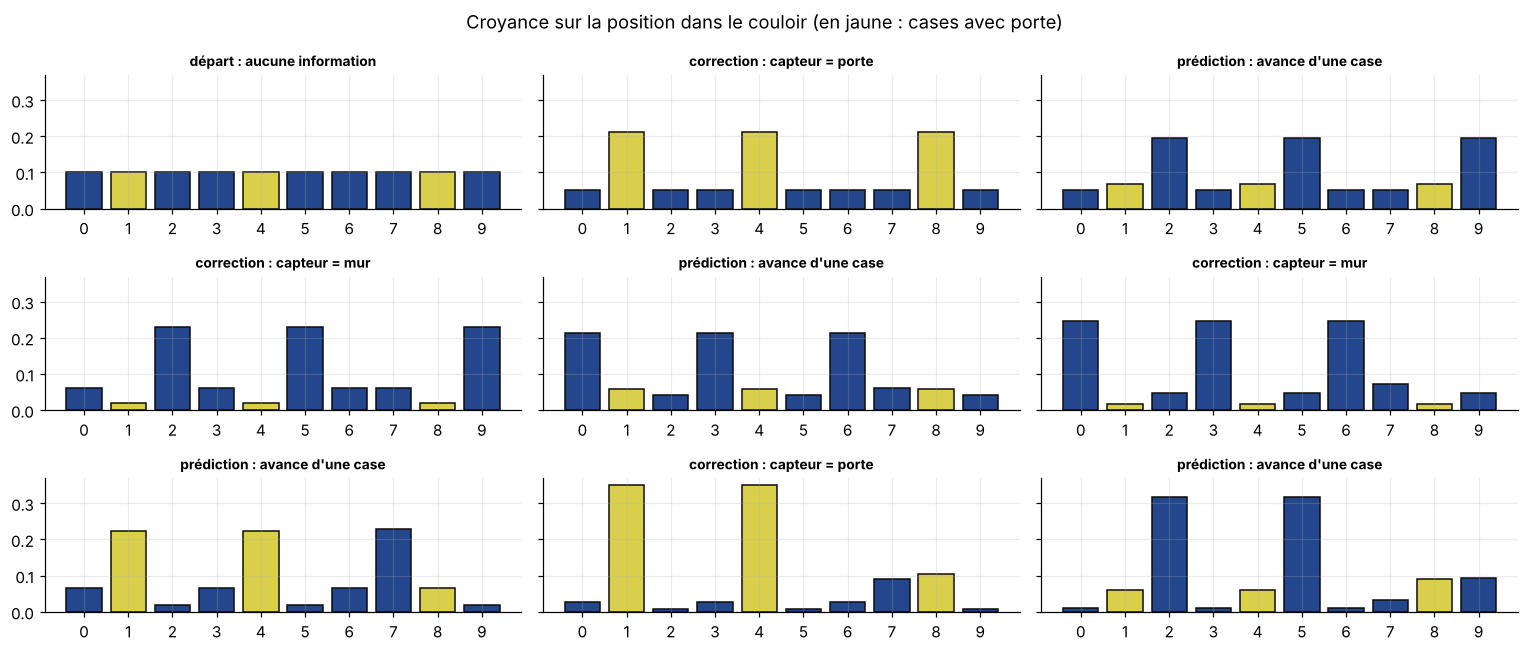

In [7]:
portes = np.array([0, 1, 0, 0, 1, 0, 0, 0, 1, 0])
FIABILITE = 0.8   # probabilité que le capteur dise vrai
GLISSEMENT_1D = 0.1


def corriger_1d(croyance, mesure):
    vraisemblance = np.where(portes == mesure, FIABILITE, 1 - FIABILITE)
    posterieure = vraisemblance * croyance
    return posterieure / posterieure.sum()


def predire_1d(croyance):
    """Le robot avance d'une case vers la droite (couloir circulaire pour simplifier)."""
    return (1 - GLISSEMENT_1D) * np.roll(croyance, 1) + GLISSEMENT_1D * croyance


croyance = np.full(10, 0.1)
etapes = [("départ : aucune information", croyance)]
for mesure in [1, 0, 0, 1]:  # le robot part de la case 1 et avance : porte, mur, mur, porte
    croyance = corriger_1d(croyance, mesure)
    etapes.append((f"correction : capteur = {'porte' if mesure else 'mur'}", croyance))
    croyance = predire_1d(croyance)
    etapes.append(("prédiction : avance d'une case", croyance))

fig, axes = plt.subplots(3, 3, figsize=(14, 6), sharey=True)
for ax, (titre, c) in zip(axes.ravel(), etapes):
    ax.bar(range(10), c, color=[JAUNE if p else BLEU for p in portes], edgecolor=NOIR)
    ax.set_title(titre, fontsize=9)
    ax.set_xticks(range(10))
fig.suptitle("Croyance sur la position dans le couloir (en jaune : cases avec porte)")
plt.tight_layout()
plt.show()

Après quatre mesures, la croyance s'est concentrée sur la bonne case : la séquence « porte, mur, mur, porte » n'est compatible qu'avec un départ en case 1.

### 3.2 Le même filtre dans l'entrepôt

La cellule suivante implémente les deux étapes sur la grille. La vraisemblance compare les 8 distances lues à celles que le lidar donnerait dans chaque cellule de la carte statique. Le terme `plancher` représente la probabilité qu'une mesure soit aberrante (chariot de passage, rayon perdu) : sans lui, une seule mesure aberrante annulerait la bonne hypothèse.

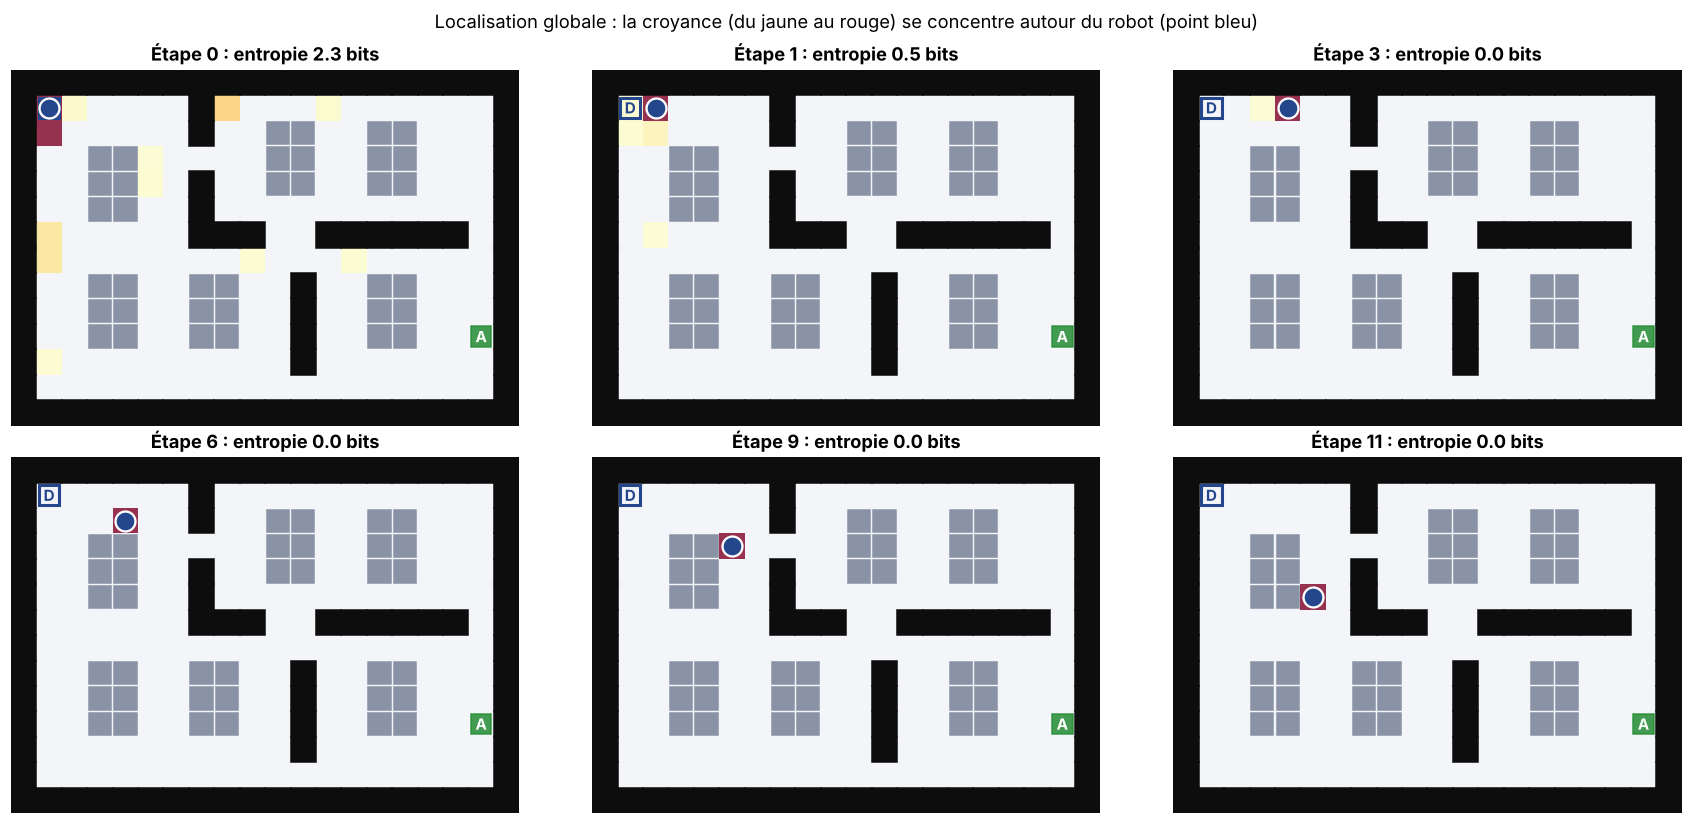

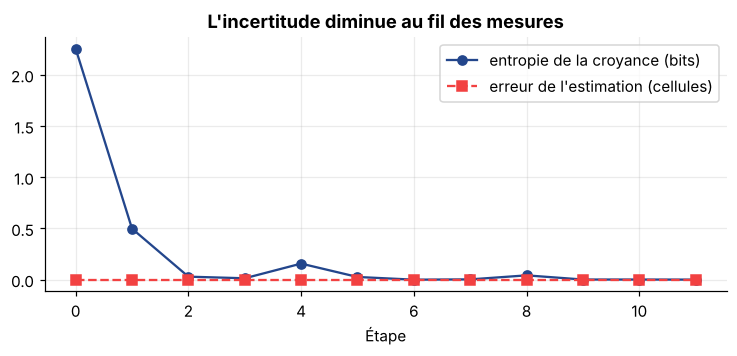

In [8]:
# PARAMÈTRES MODIFIABLES : modèle interne du filtre.
PARAMETRES_FILTRE = {"glissement": 0.15, "sigma": 0.6, "plancher": 0.05}

monde = creer_scenario("entrepot", chariots=False, graine=11, bruit_lidar=0.5, glissement=0.15)
LIBRE = monde.grille_statique() == 0
# Lidar attendu dans chaque cellule libre, calculé une fois sur la carte.
ATTENDU = np.zeros((8, monde.hauteur, monde.largeur))
for (x, y) in monde.cellules_libres():
    for k, d in enumerate(monde.lidar_exact((x, y), statique_seul=True).values()):
        ATTENDU[k, y, x] = d


def predire(croyance, action, glissement):
    """Prédiction : déplacer la masse de probabilité selon l'action."""
    if action == "ATTENDRE":
        return croyance
    dx, dy = ACTIONS[action]
    nouvelle = np.zeros_like(croyance)
    for y, x in zip(*np.nonzero(croyance)):
        if LIBRE[y + dy, x + dx]:
            nouvelle[y + dy, x + dx] += (1 - glissement) * croyance[y, x]
            nouvelle[y, x] += glissement * croyance[y, x]
        else:
            nouvelle[y, x] += croyance[y, x]   # mur : le robot reste sur place
    return nouvelle


def corriger(croyance, lidar, sigma, plancher):
    """Correction : pondérer par la vraisemblance des 8 rayons, puis normaliser."""
    vraisemblance = np.ones_like(croyance)
    for k, nom in enumerate(RAYONS):
        ecart = lidar[nom] - ATTENDU[k]
        vraisemblance *= (1 - plancher) * np.exp(-0.5 * (ecart / sigma) ** 2) + plancher
    posterieure = croyance * vraisemblance * LIBRE
    return posterieure / posterieure.sum()


def entropie(croyance):
    p = croyance[croyance > 0]
    return float(-(p * np.log2(p)).sum())


# Localisation globale : le robot ne connaît pas sa position de départ.
croyance = LIBRE / LIBRE.sum()
observation = monde.reinitialiser()
actions = ["E", "E", "E", "S", "S", "S", "E", "E", "S", "S", "S", "E"]
photos, entropies, erreurs = [], [], []
for t, action in enumerate(actions):
    croyance = corriger(croyance, observation["lidar"], PARAMETRES_FILTRE["sigma"], PARAMETRES_FILTRE["plancher"])
    y, x = np.unravel_index(croyance.argmax(), croyance.shape)
    entropies.append(entropie(croyance))
    erreurs.append(abs(x - monde.robot[0]) + abs(y - monde.robot[1]))
    if t in (0, 1, 3, 6, 9, 11):
        photos.append((t, croyance.copy(), monde.robot))
    monde.avancer(action)
    croyance = predire(croyance, action, PARAMETRES_FILTRE["glissement"])
    observation = monde.observer()

fig, axes = plt.subplots(2, 3, figsize=(16, 7.6))
for ax, (t, c, robot) in zip(axes.ravel(), photos):
    dessiner_monde(monde, ax, croyance=c, robot=robot, titre=f"Étape {t} : entropie {entropie(c):.1f} bits")
fig.suptitle("Localisation globale : la croyance (du jaune au rouge) se concentre autour du robot (point bleu)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(entropies, "o-", color=BLEU, label="entropie de la croyance (bits)")
ax.plot(erreurs, "s--", color=ROUGE, label="erreur de l'estimation (cellules)")
ax.set_xlabel("Étape")
ax.set_title("L'incertitude diminue au fil des mesures")
ax.legend()
plt.show()

Avant toute mesure, la croyance est uniforme : environ 7,5 bits d'entropie, soit près de 180 cellules possibles. La première lecture du lidar la ramène à environ 2 bits (quelques coins de l'entrepôt se ressemblent), et quelques déplacements suffisent à lever le doute. L'entropie est un indicateur que le robot peut calculer lui-même : il sait à quel point il doute.

La classe `FiltreHistogramme` du paquet réalise le même calcul. Vérification :

In [9]:
monde.reinitialiser()
filtre = FiltreHistogramme(monde, glissement=PARAMETRES_FILTRE["glissement"], bruit_lidar=PARAMETRES_FILTRE["sigma"], plancher=PARAMETRES_FILTRE["plancher"])
filtre.initialiser()                   # position inconnue
croyance = LIBRE / LIBRE.sum()
observation = monde.observer()
for action in actions[:6]:
    filtre.corriger(observation["lidar"])
    croyance = corriger(croyance, observation["lidar"], PARAMETRES_FILTRE["sigma"], PARAMETRES_FILTRE["plancher"])
    monde.avancer(action)
    filtre.predire(action)
    croyance = predire(croyance, action, PARAMETRES_FILTRE["glissement"])
    observation = monde.observer()
print("Écart maximal entre les deux implémentations :", float(np.abs(filtre.croyance - croyance).max()))
print("Estimation du filtre :", filtre.estimation(), " position réelle :", monde.robot)

Écart maximal entre les deux implémentations : 0.0
Estimation du filtre : (4, 2)  position réelle : (4, 2)


### Exercice 1. Sensibilité du filtre à son modèle

Le filtre suppose un niveau de bruit (`sigma`) et un taux de mesures aberrantes (`plancher`). Que se passe-t-il si ce modèle interne ne correspond pas à la réalité ? Faites varier `SIGMA_MODELE` alors que le bruit réel du lidar reste à 0,5, et observez l'erreur moyenne de localisation.

In [10]:
# À VOUS : choisissez les valeurs du modèle interne à tester.
SIGMA_MODELE = [0.6]
PLANCHER = 0.05


def erreur_localisation(sigma, plancher, bruit_reel=0.5, graines=range(6), chariots=True):
    """Erreur moyenne (en cellules) de l'estimation le long d'un trajet, position de départ inconnue."""
    erreurs = []
    for g in graines:
        m = creer_scenario("entrepot", chariots=chariots, graine=g, bruit_lidar=bruit_reel, glissement=0.15)
        f = FiltreHistogramme(m, glissement=0.15, bruit_lidar=sigma, plancher=plancher)
        f.initialiser()
        obs = m.reinitialiser()
        for a in actions:
            f.corriger(obs["lidar"])
            e = f.estimation()
            erreurs.append(abs(e[0] - m.robot[0]) + abs(e[1] - m.robot[1]))
            m.avancer(a)
            f.predire(a)
            obs = m.observer()
    return float(np.mean(erreurs))


for sigma in SIGMA_MODELE:
    print(f"sigma du modèle = {sigma} : erreur moyenne {erreur_localisation(sigma, PLANCHER):.2f} cellule(s)")

sigma du modèle = 0.6 : erreur moyenne 0.11 cellule(s)


**Solution possible.** On balaie `sigma` et `plancher`.

In [11]:
sigmas, planchers = [0.3, 0.6, 1.0, 2.0, 4.0], [0.0001, 0.05, 0.3]
tableau = pd.DataFrame([[erreur_localisation(s, p) for s in sigmas] for p in planchers],
                       index=[f"plancher = {p}" for p in planchers], columns=[f"sigma = {s}" for s in sigmas]).round(2)
print("Erreur moyenne de localisation (cellules), bruit réel du lidar : 0,5, chariots en circulation")
print("Un sigma trop faible rend le filtre trop sûr de lui : une mesure bruitée élimine la bonne hypothèse.")
print("Un sigma trop fort dilue l'information : toutes les cellules se ressemblent et la localisation est lente.")
tableau

Erreur moyenne de localisation (cellules), bruit réel du lidar : 0,5, chariots en circulation
Un sigma trop faible rend le filtre trop sûr de lui : une mesure bruitée élimine la bonne hypothèse.
Un sigma trop fort dilue l'information : toutes les cellules se ressemblent et la localisation est lente.


,sigma = 0.3,sigma = 0.6,sigma = 1.0,sigma = 2.0,sigma = 4.0
plancher = 0.0001,0.78,0.11,0.11,0.12,0.24
plancher = 0.05,0.44,0.11,0.11,0.12,0.24
plancher = 0.3,0.39,0.36,0.12,0.18,0.50


## Partie 4. Politique simple contre politique améliorée

Deux agents partagent la même architecture hybride (plan A* et couche réactive). Ils ne diffèrent que par la position qu'ils utilisent pour décider :

- `AgentNaif` : la position mesurée brute ;
- `AgentRobuste` : la position estimée par le filtre bayésien, à partir du lidar et de la carte uniquement (il n'utilise pas la position mesurée, ce qui le rend insensible à `bruit_position`). Si l'entropie de la croyance dépasse un seuil, il attend une étape pour accumuler des mesures.

L'environnement est dynamique : deux chariots circulent et une palette est déposée en cours de route.

In [12]:
# PARAMÈTRES MODIFIABLES : campagne de comparaison.
PARAMETRES_CAMPAGNE = {
    "niveaux": {"faible": 0.3, "moyen": 0.8, "fort": 1.5},   # bruit_position par niveau
    "bruit_lidar": 0.4,
    "glissement": 0.15,
    "graines": 8,
    "max_etapes": 200,
}


def fabriquer(bruit_position, graine):
    return creer_scenario("entrepot", evenements=[PALETTE], graine=graine, bruit_position=bruit_position,
                          bruit_lidar=PARAMETRES_CAMPAGNE["bruit_lidar"], glissement=PARAMETRES_CAMPAGNE["glissement"])


def campagne(agents, niveaux=None):
    lignes = []
    for niveau, bruit in (niveaux or PARAMETRES_CAMPAGNE["niveaux"]).items():
        for nom, fabrique in agents.items():
            for g in range(PARAMETRES_CAMPAGNE["graines"]):
                b = simuler(fabriquer(bruit, g), fabrique(), max_etapes=PARAMETRES_CAMPAGNE["max_etapes"]).bilan
                lignes.append({"niveau": niveau, "agent": nom, "graine": g, "succès": b["succes"], "étapes": b["etapes"],
                               "collisions": b["collisions"], "décision (ms)": b["temps_decision_moyen_ms"]})
    return pd.DataFrame(lignes)


resultats = campagne({"naïf": AgentNaif, "robuste": lambda: AgentRobuste(glissement=0.15, bruit_lidar=0.6)})
bilan = resultats.groupby(["niveau", "agent"], sort=False).agg(**{"succès (%)": ("succès", lambda s: 100 * s.mean()), "étapes (médiane)": ("étapes", "median"),
                                                                    "collisions (moyenne)": ("collisions", "mean"), "décision (ms)": ("décision (ms)", "mean")}).round(2)
bilan

succès (%)  étapes (médiane)  collisions (moyenne)  \
niveau agent                                                         
faible naïf          100.0              37.0                  0.25   
       robuste       100.0              36.5                  0.00   
moyen  naïf          100.0              71.0                  0.25   
       robuste       100.0              36.5                  0.00   
fort   naïf          100.0             134.0                  1.75   
       robuste       100.0              36.5                  0.00   

                décision (ms)  
niveau agent                   
faible naïf              0.02  
       robuste           0.15  
moyen  naïf              0.04  
       robuste           0.13  
fort   naïf              0.04  
       robuste           0.13

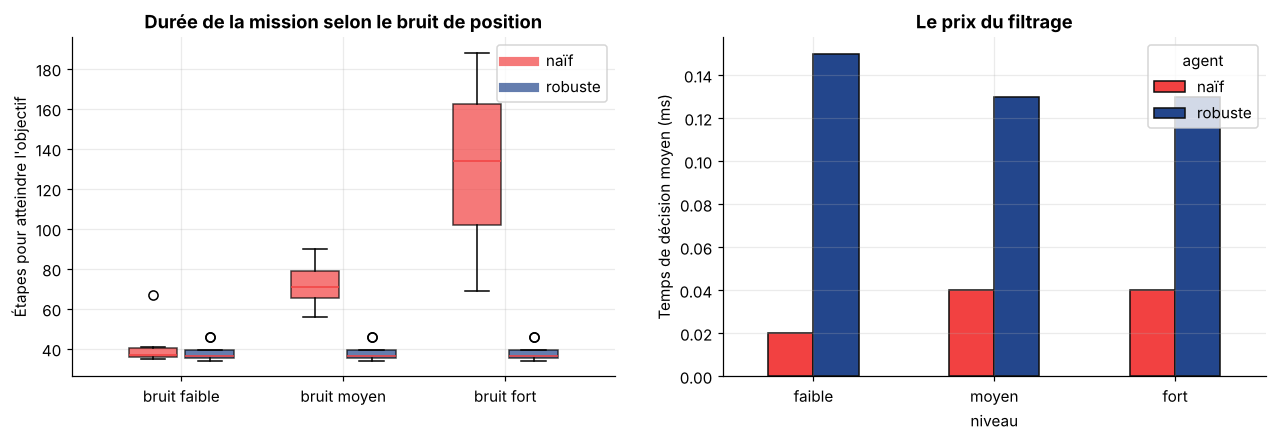

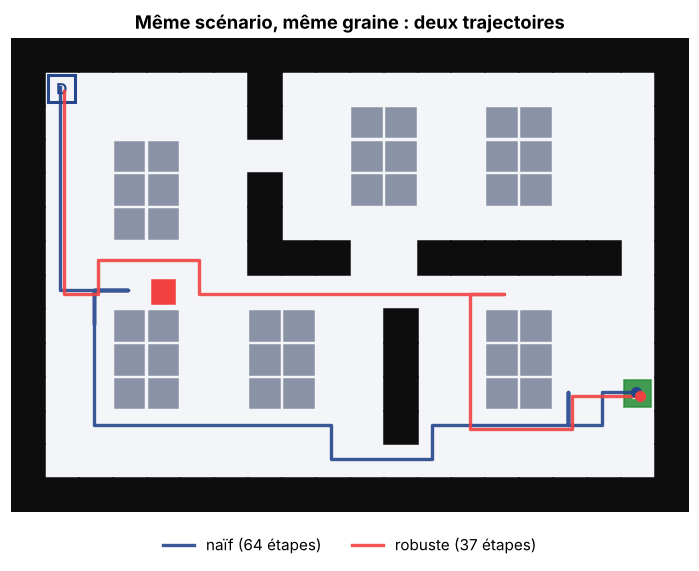

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
niveaux = list(PARAMETRES_CAMPAGNE["niveaux"])
for k, (nom, couleur) in enumerate((("naïf", ROUGE), ("robuste", BLEU))):
    donnees = [resultats[(resultats["niveau"] == n) & (resultats["agent"] == nom)]["étapes"] for n in niveaux]
    boites = axes[0].boxplot(donnees, positions=np.arange(len(niveaux)) + (k - 0.5) * 0.35, widths=0.3, patch_artist=True)
    for b in boites["boxes"]:
        b.set_facecolor(couleur)
        b.set_alpha(0.7)
    axes[0].plot([], [], color=couleur, lw=6, alpha=0.7, label=nom)
axes[0].set_xticks(range(len(niveaux)), [f"bruit {n}" for n in niveaux])
axes[0].set_ylabel("Étapes pour atteindre l'objectif")
axes[0].set_title("Durée de la mission selon le bruit de position")
axes[0].legend()
duree = bilan["décision (ms)"].unstack()
duree.loc[niveaux].plot.bar(ax=axes[1], color=[ROUGE, BLEU], edgecolor=NOIR, rot=0)
axes[1].set_ylabel("Temps de décision moyen (ms)")
axes[1].set_title("Le prix du filtrage")
plt.show()

naif = simuler(fabriquer(0.8, 3), AgentNaif(), max_etapes=200, identifiant="m5-naif", module=5, titre="Politique simple, position brute")
robuste = simuler(fabriquer(0.8, 3), AgentRobuste(glissement=0.15, bruit_lidar=0.6), max_etapes=200, identifiant="m5-robuste", module=5, titre="Politique améliorée, filtre bayésien")
dessiner_monde(naif.monde, trajectoires={f"naïf ({naif.bilan['etapes']} étapes)": naif.trajectoire(), f"robuste ({robuste.bilan['etapes']} étapes)": robuste.trajectoire()},
               obstacles=robuste.bilan["palettes_finales"], titre="Même scénario, même graine : deux trajectoires")
plt.show()

L'agent naïf finit par arriver, mais il hésite : chaque position fausse déclenche une replanification depuis un endroit où il n'est pas. L'agent robuste paie un temps de décision plus élevé (le filtre parcourt la grille) et gagne en régularité. Ce compromis entre coût de calcul et qualité de décision se retrouve dans tous les systèmes embarqués.

### Exercice 2 (TP du module). Implémenter votre algorithme d'autonomie

Écrivez votre propre politique en héritant de `AgentHybride`. Il suffit de redéfinir la méthode `position(observation)`, qui retourne la position utilisée pour décider. La version de départ ci-dessous fait confiance à la mesure, sauf si elle tombe dans un obstacle ou saute de plus de 2 cellules : dans ce cas, elle garde la position précédente avancée de la dernière action (navigation à l'estime).

Cette version de départ reste loin de l'agent robuste et provoque davantage de collisions que l'agent naïf. Améliorez-la, puis comparez-la aux deux agents de référence avec `campagne`. Pistes : fusionner estime et mesure, utiliser le lidar pour valider une position candidate, attendre quand le doute est trop grand.

In [14]:
class MonAgent(AgentHybride):
    """À VOUS : votre politique d'autonomie."""

    nom = "mon_agent"
    architecture = "hybride, estime corrigée par la mesure"

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.estime = tuple(monde.depart)
        self.derniere_action = "ATTENDRE"

    def position(self, observation):
        # 1. Navigation à l'estime : on suppose que la dernière action a réussi.
        dx, dy = ACTIONS[self.derniere_action]
        predite = (self.estime[0] + dx, self.estime[1] + dy)
        if not self.monde.est_libre_statique(predite):
            predite = self.estime
        # 2. Mesure : acceptée si elle est plausible.
        mesure = tuple(observation["position"])
        saut = abs(mesure[0] - predite[0]) + abs(mesure[1] - predite[1])
        self.estime = mesure if self.monde.est_libre_statique(mesure) and saut <= 2 else predite
        return self.estime

    def decider(self, observation):
        action, infos = super().decider(observation)
        self.derniere_action = action
        return action, infos


essai = campagne({"naïf": AgentNaif, "mon agent": MonAgent, "robuste": lambda: AgentRobuste(glissement=0.15, bruit_lidar=0.6)}, niveaux={"moyen": 0.8})
essai.groupby("agent", sort=False).agg(**{"succès (%)": ("succès", lambda s: 100 * s.mean()), "étapes (médiane)": ("étapes", "median"), "collisions (moyenne)": ("collisions", "mean")})

,succès (%),étapes (médiane),collisions (moyenne)
agent,,,
naïf,100.0,71.0,0.25
mon agent,100.0,65.0,1.00
robuste,100.0,36.5,0.00


**Solution possible.** On valide chaque position candidate avec le lidar : parmi la position prédite, la mesure et leurs voisines, on retient la cellule dont le lidar attendu ressemble le plus au lidar lu. C'est une version très allégée de l'étape de correction du filtre, limitée à quelques cellules.

In [15]:
class AgentEstimeLidar(MonAgent):
    nom = "estime_lidar"
    architecture = "hybride, estime validée par le lidar"

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.attendu = {c: monde.lidar_exact(c, statique_seul=True) for c in monde.cellules_libres()}

    def position(self, observation):
        dx, dy = ACTIONS[self.derniere_action]
        predite = (self.estime[0] + dx, self.estime[1] + dy)
        if not self.monde.est_libre_statique(predite):
            predite = self.estime
        # Candidates : la prédiction, la position précédente (glissement) et leurs voisines directes.
        candidates = {predite, self.estime}
        for c in list(candidates):
            candidates |= {(c[0] + ax, c[1] + ay) for ax, ay in ((1, 0), (-1, 0), (0, 1), (0, -1))}
        candidates = [c for c in candidates if c in self.attendu]

        def desaccord(c):
            ecarts = sorted(abs(observation["lidar"][r] - self.attendu[c][r]) for r in RAYONS)
            return sum(ecarts[:6]) + 0.3 * (c != predite)   # on ignore les 2 rayons les plus aberrants

        self.estime = min(candidates, key=desaccord)
        return self.estime


solution = campagne({"naïf": AgentNaif, "mon agent": MonAgent, "estime et lidar": AgentEstimeLidar,
                     "robuste": lambda: AgentRobuste(glissement=0.15, bruit_lidar=0.6)})
solution.groupby(["niveau", "agent"], sort=False).agg(**{"succès (%)": ("succès", lambda s: 100 * s.mean()), "étapes (médiane)": ("étapes", "median"),
                                                          "collisions (moyenne)": ("collisions", "mean"), "décision (ms)": ("décision (ms)", "mean")}).round(2)

succès (%)  étapes (médiane)  collisions (moyenne)  \
niveau agent                                                                 
faible naïf                  100.0              37.0                  0.25   
       mon agent             100.0              38.0                  0.25   
       estime et lidar       100.0              36.5                  0.12   
       robuste               100.0              36.5                  0.00   
moyen  naïf                  100.0              71.0                  0.25   
       mon agent             100.0              65.0                  1.00   
       estime et lidar       100.0              36.5                  0.12   
       robuste               100.0              36.5                  0.00   
fort   naïf                  100.0             134.0                  1.75   
       mon agent              75.0             110.5                  1.88   
       estime et lidar       100.0              36.5                  0.12   
       robuste               100.0              36.5                  0.00   

                        décision (ms)  
niveau agent                           
faible naïf                      0.02  
       mon agent                 0.02  
       estime et lidar           0.03  
       robuste                   0.14  
moyen  naïf                      0.04  
       mon agent                 0.04  
       estime et lidar           0.03  
       robuste                   0.14  
fort   naïf                      0.04  
       mon agent                 0.04  
       estime et lidar           0.03  
       robuste                   0.17

## Partie 5. Apprentissage par renforcement

Jusqu'ici, le comportement du robot était programmé. On peut aussi le laisser **apprendre** par essais et erreurs. Le Q-learning estime, pour chaque couple (état, action), la valeur Q(s, a) : le gain cumulé attendu si le robot fait l'action a dans l'état s puis agit au mieux.

Après chaque transition (s, a, r, s'), la table est corrigée :

Q(s, a) ← Q(s, a) + α × [ r + γ × max Q(s', ·) - Q(s, a) ]

- α : taux d'apprentissage ;
- γ : facteur d'actualisation (poids du futur) ;
- ε : probabilité de choisir une action au hasard (exploration).

Récompenses : +10 à l'objectif, -1 pour un choc contre un mur, -0,05 par pas (pour préférer les chemins courts).

### 5.1 Un petit cas, écrit à la main

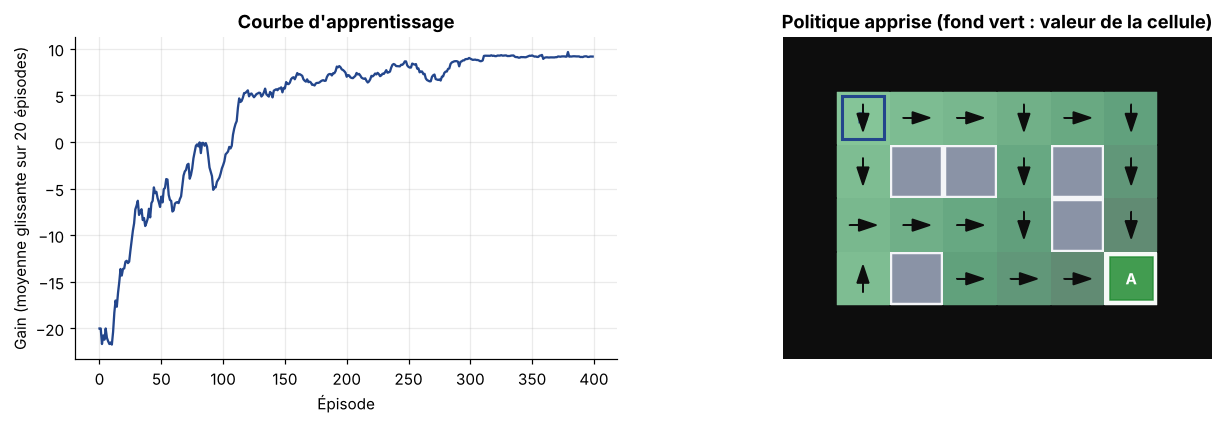

In [16]:
PETIT_PLAN = [
    "########",
    "#D.....#",
    "#.RR.R.#",
    "#....R.#",
    "#.R...A#",
    "########",
]
petit = Entrepot(plan=PETIT_PLAN, nom="petit")

# PARAMÈTRES MODIFIABLES : apprentissage sur le petit cas.
PARAMETRES_Q = {"episodes": 400, "alpha": 0.5, "gamma": 0.95, "epsilon_debut": 1.0, "epsilon_fin": 0.05, "glissement": 0.1, "horizon": 60}


def q_learning(monde, episodes, alpha, gamma, epsilon_debut, epsilon_fin, glissement, horizon, graine=4130):
    """Q-learning tabulaire séquentiel. Retourne la table Q (hauteur, largeur, 5) et les gains par épisode."""
    rng = np.random.default_rng(graine)
    Q = np.zeros((monde.hauteur, monde.largeur, 5))
    libres = monde.cellules_libres()
    gains = []
    for ep in range(episodes):
        eps = epsilon_debut + (epsilon_fin - epsilon_debut) * ep / (episodes - 1)
        x, y = libres[rng.integers(len(libres))]            # départ aléatoire pour tout explorer
        gain = 0.0
        for _ in range(horizon):
            if (x, y) == monde.objectif:
                break
            a = int(rng.integers(5)) if rng.random() < eps else int(Q[y, x].argmax())   # exploration ou exploitation
            dx, dy = ACTIONS[NOMS_ACTIONS[a]] if rng.random() >= glissement else (0, 0)
            nx, ny = x + dx, y + dy
            choc = not monde.est_libre_statique((nx, ny))
            if choc:
                nx, ny = x, y
            arrive = (nx, ny) == monde.objectif
            r = -0.05 - 1.0 * choc + 10.0 * arrive
            cible = r + (0.0 if arrive else gamma * Q[ny, nx].max())
            Q[y, x, a] += alpha * (cible - Q[y, x, a])       # mise à jour du Q-learning
            x, y, gain = nx, ny, gain + r
        gains.append(gain)
    return Q, gains


def dessiner_politique(monde, Q, ax=None, titre=None):
    """Carte de la politique gloutonne : une flèche par cellule, sur fond de valeur maximale."""
    valeur = Q.max(-1).astype(float)
    valeur[monde.grille_statique() == 1] = np.nan
    ax = dessiner_monde(monde, ax, titre=titre)
    ax.imshow(valeur, extent=(0, monde.largeur, monde.hauteur, 0), cmap="Greens", alpha=0.6, zorder=1)
    for (x, y) in monde.cellules_libres():
        if (x, y) == monde.objectif:
            continue
        dx, dy = ACTIONS[NOMS_ACTIONS[int(Q[y, x].argmax())]]
        if (dx, dy) == (0, 0):
            ax.scatter([x + 0.5], [y + 0.5], s=12, color=NOIR, zorder=5)
        else:
            ax.arrow(x + 0.5 - 0.25 * dx, y + 0.5 - 0.25 * dy, 0.5 * dx, 0.5 * dy, head_width=0.22, length_includes_head=True, color=NOIR, zorder=5)
    return ax


Q_petit, gains = q_learning(petit, **PARAMETRES_Q)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(pd.Series(gains).rolling(20, min_periods=1).mean(), color=BLEU)
axes[0].set_xlabel("Épisode")
axes[0].set_ylabel("Gain (moyenne glissante sur 20 épisodes)")
axes[0].set_title("Courbe d'apprentissage")
dessiner_politique(petit, Q_petit, axes[1], "Politique apprise (fond vert : valeur de la cellule)")
plt.show()

### 5.2 Passage à l'échelle : des centaines de robots apprennent en parallèle

La boucle ci-dessus traite une transition à la fois. La fonction `q_learning_lot` fait avancer des centaines de robots en même temps dans la même table Q, sous forme de tenseurs PyTorch. C'est un calcul que le GPU accélère, contrairement à la planification A*, qui reste séquentielle et sur CPU.

Apprentissage sur cpu : 1.8 s  au plus 6 144 000 transitions  soit environ 3 500 855 par seconde
Version séquentielle en Python : au plus 170 322 transitions par seconde
Pas de GPU détecté : la comparaison CPU / GPU est ignorée. Avec CUDA, augmentez `lot` à 8192 pour voir l'écart se creuser.


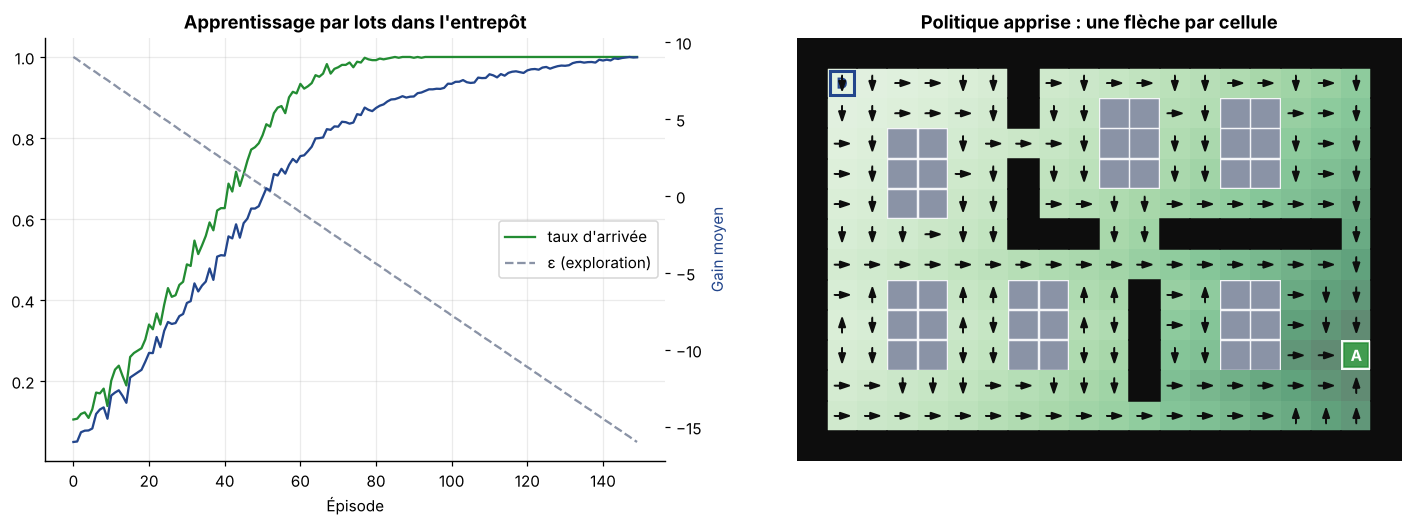

In [17]:
# PARAMÈTRES MODIFIABLES : apprentissage par lots dans l'entrepôt.
PARAMETRES_LOT = {"episodes": 150, "lot": 512, "horizon": 80, "alpha": 0.5, "gamma": 0.95, "glissement": 0.1}
entrepot = creer_scenario("entrepot", chariots=False)

appris = q_learning_lot(entrepot, appareil=APPAREIL, **PARAMETRES_LOT)
transitions = PARAMETRES_LOT["episodes"] * PARAMETRES_LOT["lot"] * PARAMETRES_LOT["horizon"]
print(f"Apprentissage sur {appris['appareil']} : {appris['duree_s']:.1f} s, au plus {transitions:,d} transitions, soit environ {transitions / appris['duree_s']:,.0f} par seconde".replace(",", " "))
debut = time.perf_counter()
q_learning(entrepot, episodes=40, alpha=0.5, gamma=0.95, epsilon_debut=1.0, epsilon_fin=0.05, glissement=0.1, horizon=80)
print(f"Version séquentielle en Python : au plus {40 * 80 / (time.perf_counter() - debut):,.0f} transitions par seconde".replace(",", " "))
if str(APPAREIL) != "cpu":
    cpu = q_learning_lot(entrepot, appareil="cpu", **PARAMETRES_LOT)
    print(f"Même lot sur CPU : {cpu['duree_s']:.1f} s, soit un facteur {cpu['duree_s'] / appris['duree_s']:.1f} en faveur du GPU")
else:
    print("Pas de GPU détecté : la comparaison CPU / GPU est ignorée. Avec CUDA, augmentez `lot` à 8192 pour voir l'écart se creuser.")

courbe = pd.DataFrame(appris["courbe"])
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(courbe["episode"], courbe["taux_arrivee"], color=VERT, label="taux d'arrivée")
axes[0].plot(courbe["episode"], courbe["epsilon"], color=GRIS, ls="--", label="ε (exploration)")
axes[0].set_xlabel("Épisode")
axes[0].set_title("Apprentissage par lots dans l'entrepôt")
axes[0].legend(loc="center right")
ax2 = axes[0].twinx()
ax2.plot(courbe["episode"], courbe["gain_moyen"], color=BLEU)
ax2.set_ylabel("Gain moyen", color=BLEU)
ax2.grid(False)
dessiner_politique(entrepot, appris["Q"], axes[1], "Politique apprise : une flèche par cellule")
plt.show()

### 5.3 La politique apprise face à l'imprévu

La table Q a été apprise dans un entrepôt **sans** chariots. On l'utilise maintenant dans l'entrepôt complet. `AgentAppris` suit la table, et une garde réactive lui interdit d'avancer vers une cellule que le lidar voit occupée : c'est encore une architecture hybride, dont la couche de décision est apprise au lieu d'être programmée.

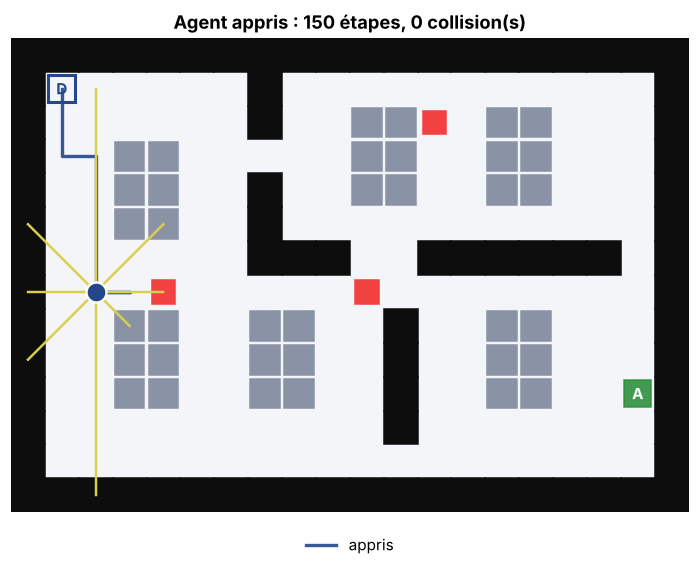

,agent,succès (%),étapes (médiane),collisions (moyenne),décision (ms)
0,appris,0.0,150.0,0.0,0.008
1,hybride (A*),100.0,35.5,0.0,0.010


In [18]:
lignes = []
for nom, fabrique in (("appris", lambda: AgentAppris(appris["Q"])), ("hybride (A*)", AgentHybride)):
    bilans = [simuler(creer_scenario("entrepot", evenements=[PALETTE], glissement=0.1, graine=g), fabrique(), max_etapes=150).bilan for g in range(10)]
    lignes.append({"agent": nom, "succès (%)": 100 * np.mean([b["succes"] for b in bilans]), "étapes (médiane)": np.median([b["etapes"] for b in bilans]),
                   "collisions (moyenne)": np.mean([b["collisions"] for b in bilans]), "décision (ms)": np.mean([b["temps_decision_moyen_ms"] for b in bilans])})
trace_appris = simuler(creer_scenario("entrepot", evenements=[PALETTE], glissement=0.1, graine=1), AgentAppris(appris["Q"]), max_etapes=150,
                       identifiant="m5-appris", module=5, titre="Politique apprise par Q-learning")
dessiner_trace(trace_appris, titre=f"Agent appris : {trace_appris.bilan['etapes']} étapes, {trace_appris.bilan['collisions']} collision(s)")
plt.show()
pd.DataFrame(lignes).round(3)

La politique apprise décide très vite (une lecture de table) et tolère le glissement, puisqu'elle a une action pour chaque cellule. Elle ne sait en revanche rien des obstacles mobiles : c'est la garde réactive qui les gère, avec des détours parfois maladroits. Elle est aussi liée à un objectif fixe : changer de destination impose de réapprendre, alors que A* replanifie immédiatement.

### Exercice 3. Explorer les paramètres de l'apprentissage

Sur le petit cas, modifiez un paramètre à la fois (γ, ε final, nombre d'épisodes) et observez la politique obtenue. Que devient la politique avec γ = 0,5 ? Et sans exploration (ε = 0 du début à la fin) ?

Taux de réussite depuis le départ : 100 %


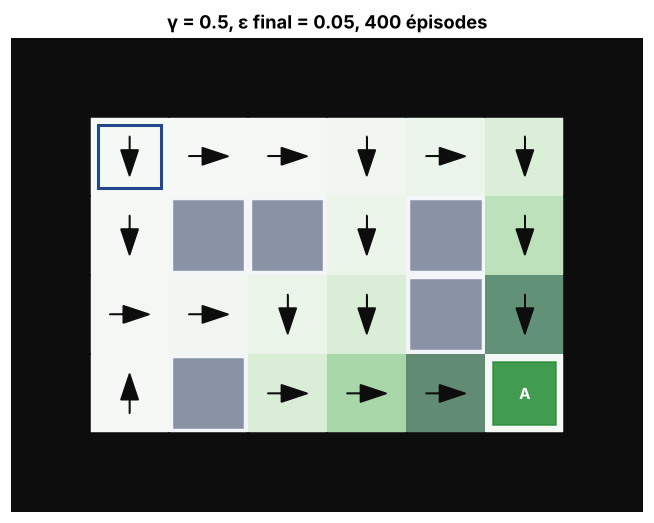

In [19]:
# À VOUS : modifiez les paramètres de l'essai.
ESSAI_Q = dict(PARAMETRES_Q, gamma=0.5)


def taux_reussite(monde, Q, essais=200, glissement=0.1, horizon=60, graine=0):
    """Part des essais où la politique gloutonne atteint l'objectif depuis le départ."""
    rng = np.random.default_rng(graine)
    reussites = 0
    for _ in range(essais):
        x, y = monde.depart
        for _ in range(horizon):
            dx, dy = ACTIONS[NOMS_ACTIONS[int(Q[y, x].argmax())]] if rng.random() >= glissement else (0, 0)
            if monde.est_libre_statique((x + dx, y + dy)):
                x, y = x + dx, y + dy
            if (x, y) == monde.objectif:
                reussites += 1
                break
    return reussites / essais


Q_essai, _ = q_learning(petit, **ESSAI_Q)
print(f"Taux de réussite depuis le départ : {100 * taux_reussite(petit, Q_essai):.0f} %")
dessiner_politique(petit, Q_essai, titre=f"γ = {ESSAI_Q['gamma']}, ε final = {ESSAI_Q['epsilon_fin']}, {ESSAI_Q['episodes']} épisodes")
plt.show()

**Solution possible.**

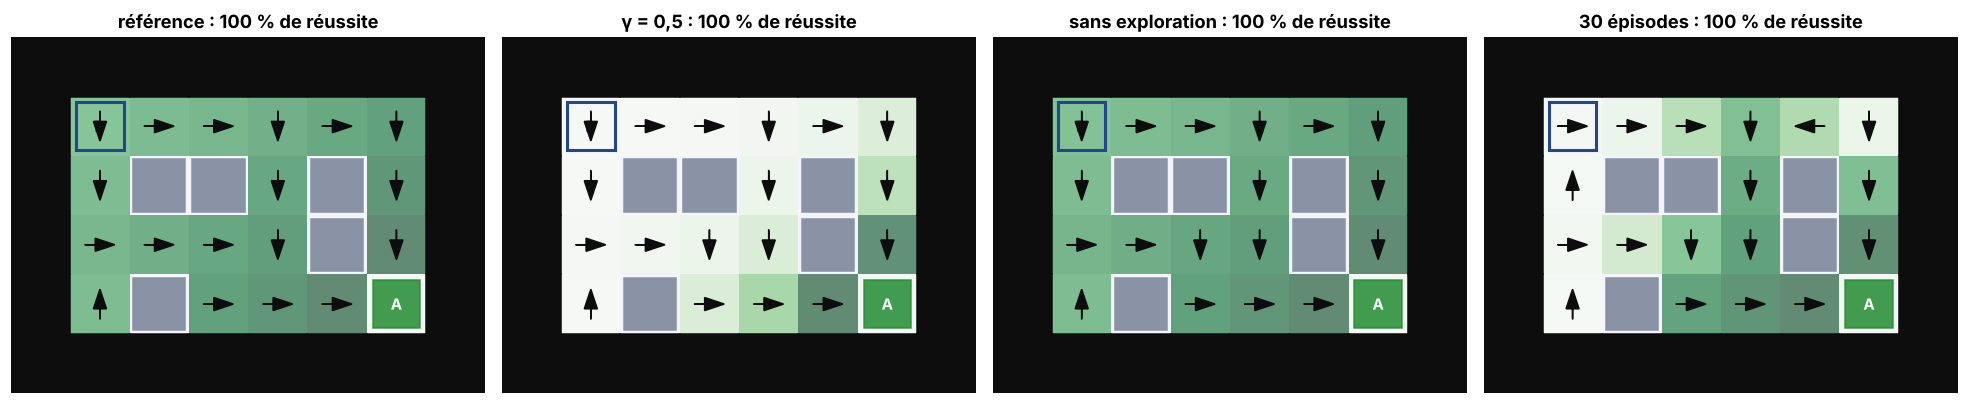

Avec un γ faible, la récompense de l'objectif s'efface vite avec la distance : loin de l'objectif, les valeurs sont presque nulles et la politique devient fragile.
Sans exploration ni assez d'épisodes, des zones entières ne sont jamais visitées : leurs flèches n'ont aucun sens.
Les départs aléatoires compensent en partie l'absence d'exploration : ils font visiter tous les états.


In [20]:
variantes = {
    "référence": PARAMETRES_Q,
    "γ = 0,5": dict(PARAMETRES_Q, gamma=0.5),
    "sans exploration": dict(PARAMETRES_Q, epsilon_debut=0.0, epsilon_fin=0.0),
    "30 épisodes": dict(PARAMETRES_Q, episodes=30),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (nom, parametres) in zip(axes, variantes.items()):
    Q_v, _ = q_learning(petit, **parametres)
    dessiner_politique(petit, Q_v, ax, f"{nom} : {100 * taux_reussite(petit, Q_v):.0f} % de réussite")
plt.tight_layout()
plt.show()
print("Avec un γ faible, la récompense de l'objectif s'efface vite avec la distance : loin de l'objectif, les valeurs sont presque nulles et la politique devient fragile.")
print("Sans exploration ni assez d'épisodes, des zones entières ne sont jamais visitées : leurs flèches n'ont aucun sens.")
print("Les départs aléatoires compensent en partie l'absence d'exploration : ils font visiter tous les états.")

## Partie 6. Export des traces

Chaque exécution produit une trace au format commun de la formation : numéro d'étape, état de l'environnement, observations, décision, action, résultat et métriques. Le même fichier JSON est rejoué par la scène 3D du site, étape par étape.

In [21]:
for trace in (naif, robuste, trace_appris):
    chemin = trace.enregistrer(RESULTATS / f"{trace.identifiant}.json")
    print(f"{chemin} : {len(trace.etapes)} étapes, {chemin.stat().st_size / 1024:.0f} Ko")

etape = robuste.vers_dict()["etapes"][10]
print("\nContenu d'une étape de la trace de l'agent robuste :")
for cle, valeur in etape.items():
    texte = str(valeur)
    print(f"  {cle:12s} {texte[:150]}{' ...' if len(texte) > 150 else ''}")

resultats/m5-naif.json : 64 étapes, 38 Ko
resultats/m5-robuste.json : 37 étapes, 24 Ko
resultats/m5-appris.json : 150 étapes, 79 Ko

Contenu d'une étape de la trace de l'agent robuste :
  t            10
  etat         {'robot': [4, 6], 'chariots': [[13, 7], [12, 4]], 'palettes': [[4, 7]]}
  observation  {'lidar': {'N': 2, 'NE': 6, 'E': 2, 'SE': 3, 'S': 1, 'SO': 4, 'O': 3, 'NO': 1}, 'position': [5, 5], 'croyance': [[4, 6, 1.0]], 'position_estimee': [4, ...
  decision     {'couche': 'reactive', 'raison': 'Obstacle imprévu : replanification, détour par E', 'plan': [[4, 6], [5, 6], [5, 7], [6, 7], [7, 7], [8, 7], [9, 7],  ...
  action       E
  resultat     {'action_executee': 'E', 'glissement': False, 'collision': False, 'arrive': False, 'evenements': []}
  metriques    {'distance': 11, 'collisions': 0, 'temps_decision_ms': 0.2367, 'distance_objectif': 17}


## Synthèse du module

- L'autonomie repose sur une boucle fermée : percevoir, décider, agir, puis recommencer. Une exécution en boucle ouverte ne résiste ni au glissement ni aux obstacles imprévus.
- L'état réel n'est jamais accessible. Le filtre bayésien discret entretient une croyance par deux opérations : prédiction (l'action étale la croyance) et correction (la mesure la concentre). Son entropie mesure le doute du robot.
- Décider à partir de la croyance plutôt que de la mesure brute raccourcit les missions quand le bruit augmente, au prix d'un temps de décision plus élevé.
- Le Q-learning apprend une politique par essais et erreurs. Elle décide très vite, mais reste liée à l'objectif et aux conditions de son apprentissage : une garde réactive reste nécessaire.
- Le GPU accélère l'apprentissage par lots (des centaines de robots simulés en tenseurs). La boucle de décision d'un robot unique et la planification A* restent sur CPU.

## Auto-évaluation

Sans relire le notebook, cochez ce que vous sauriez refaire seul sur un nouveau problème :

- [ ] Je sais programmer une boucle d'autonomie qui tient compte du bruit et du glissement.
- [ ] Je sais mettre à jour une croyance après une mesure et après un déplacement.
- [ ] Je sais comparer deux politiques sur plusieurs graines et plusieurs niveaux de bruit.
- [ ] Je sais entraîner une politique par Q-learning et l'encadrer par une garde réactive.

Pour chaque case que vous hésitez à cocher, reprenez la partie correspondante et refaites son exercice sans regarder la solution. Les trois questions de la section « Vérifiez vos acquis » du module, sur le site, complètent ce bilan.